# Debug: SegmentDataset items

Plots the full featurized utterance (via `src/debug_items.py`) for `n` random TIMIT TRAIN utterances inline,
grouped per utterance: WAV files with the same name (e.g. `SX150.WAV`) are the same sentence read by
different speakers, so each utterance's speakers are shown one after another for comparison.

Only utterances read by at least two speakers are sampled: SX sentences have 7 speakers each, SA1/SA2
all 462 (capped by `max_speakers`), SI sentences a single one (so never picked).

In [1]:
import random
import sys
import tempfile
from collections import defaultdict
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent  # notebook runs from doc/
sys.path.insert(0, str(ROOT))

from src.config import ExperimentConfig
from src.debug_items import plot_items

In [2]:
n = 1                    # number of distinct utterances
max_speakers = 3         # speakers shown per utterance (random subset if more, e.g. SA1/SA2)
seed = 0                 # picks utterances/speakers
config_path = ROOT / "configs/cnn-timit.yaml"  # transformation, None = defaults
normalise = False         # False = plot without per-frame z-scoring
full_only = False
timit_train = Path("~/.cache/datasets/timit/lisa/data/timit/raw/TIMIT/TRAIN").expanduser()

## SX349 (3 of 7 speakers)

DR2/FCYL0/SX349.WAV


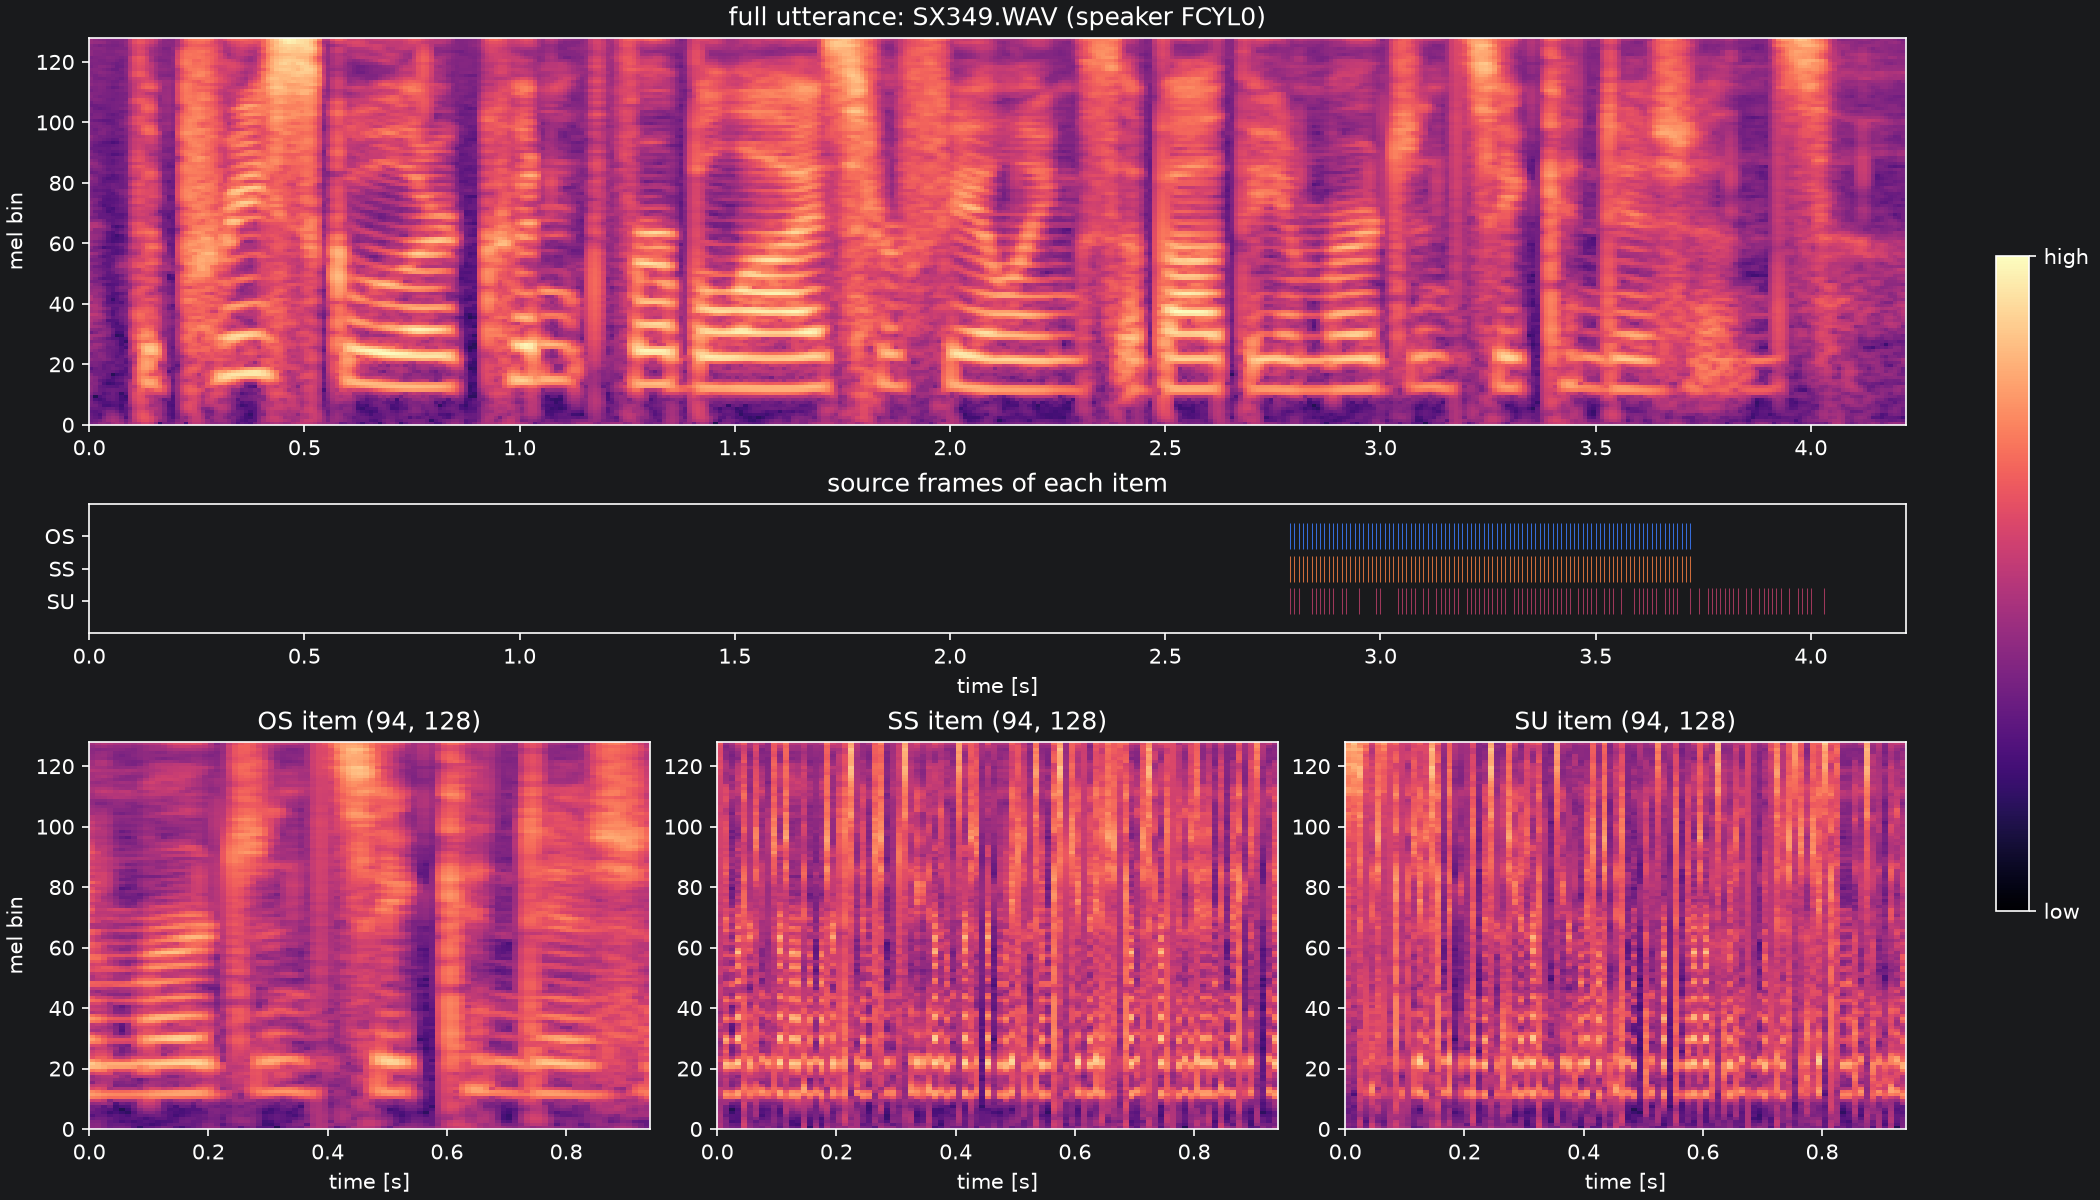

DR4/MBWP0/SX349.WAV


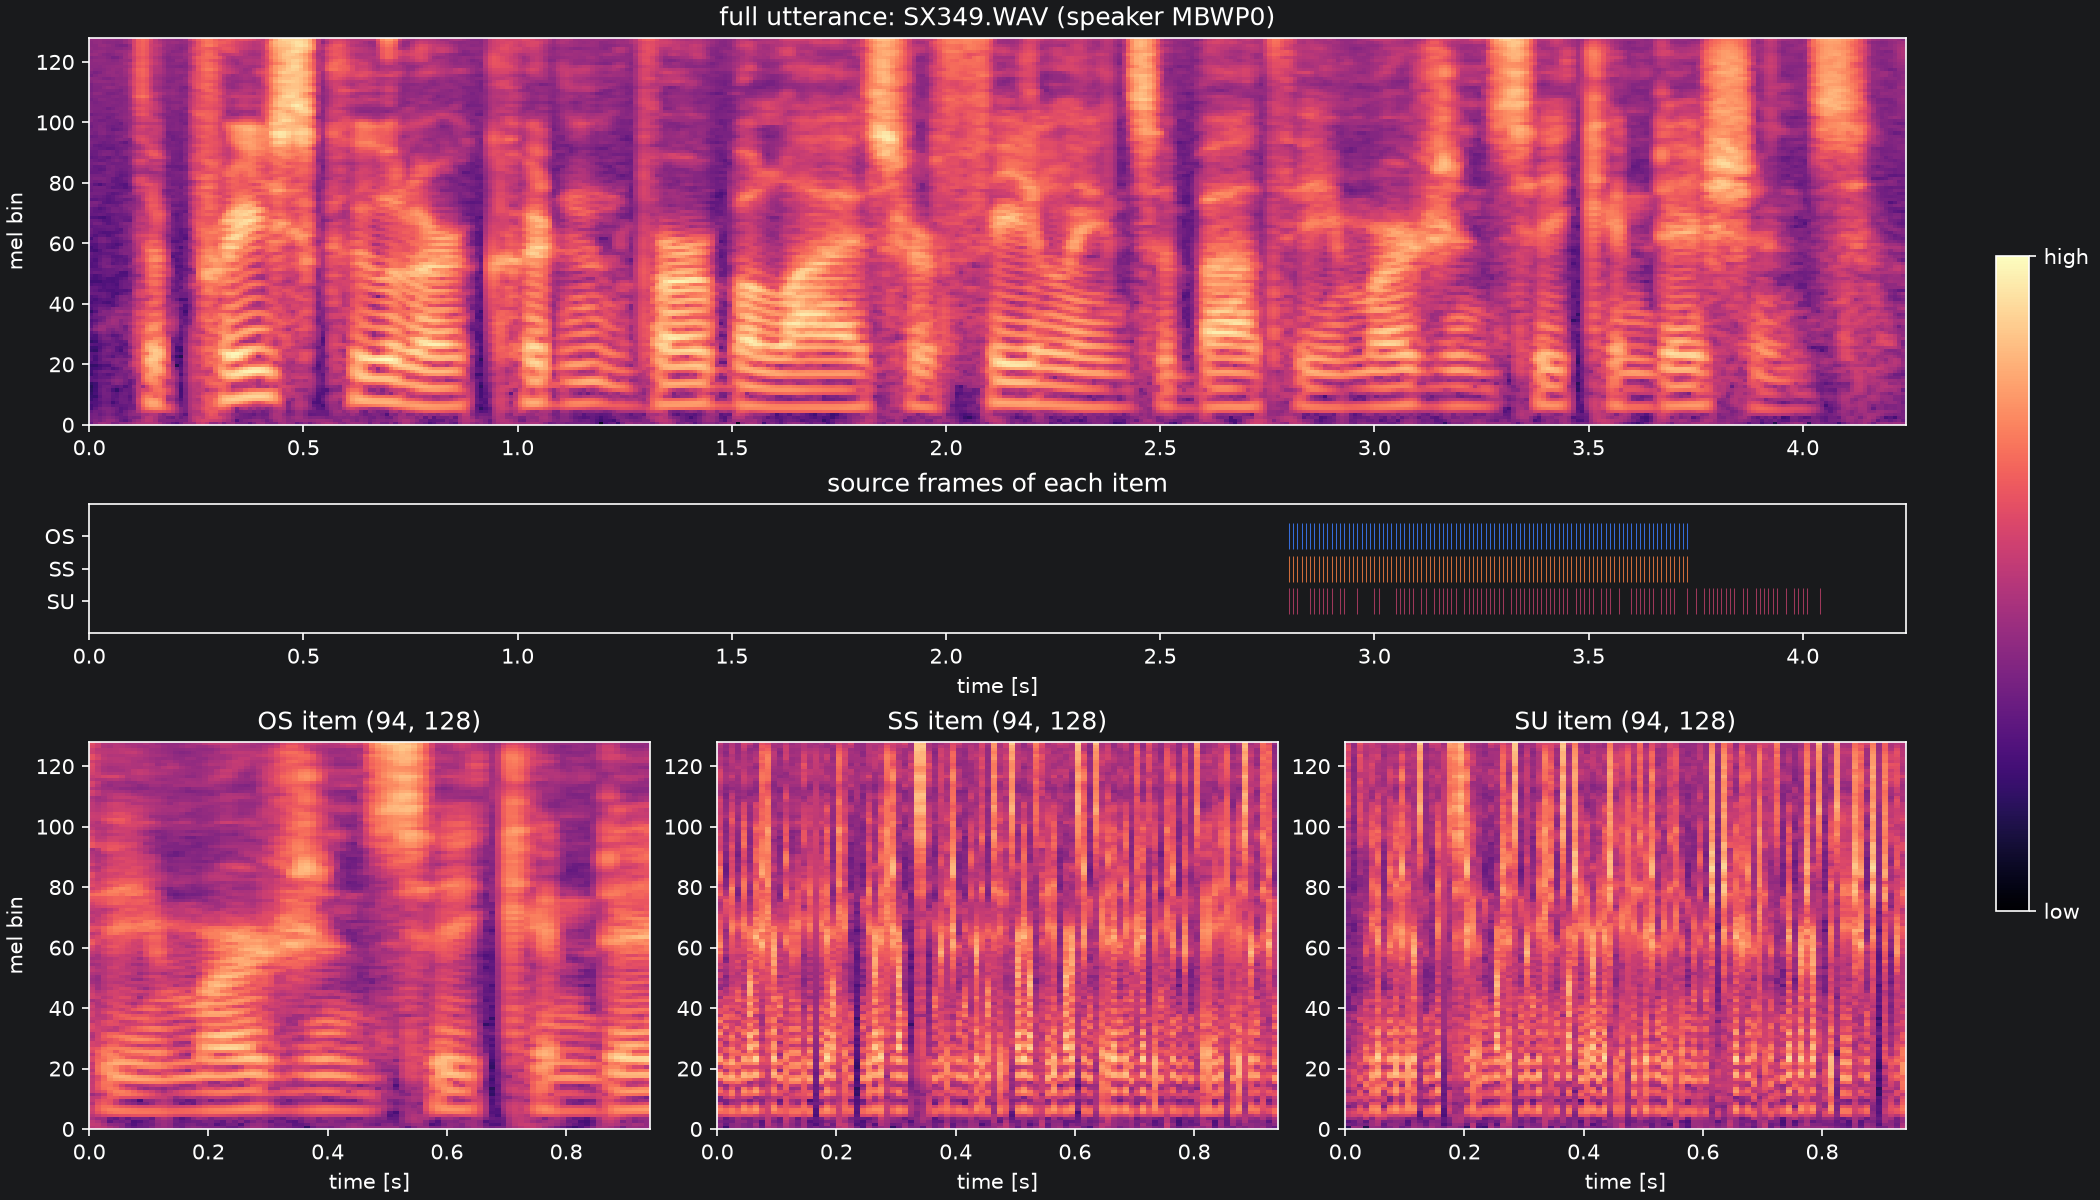

DR7/FVKB0/SX349.WAV


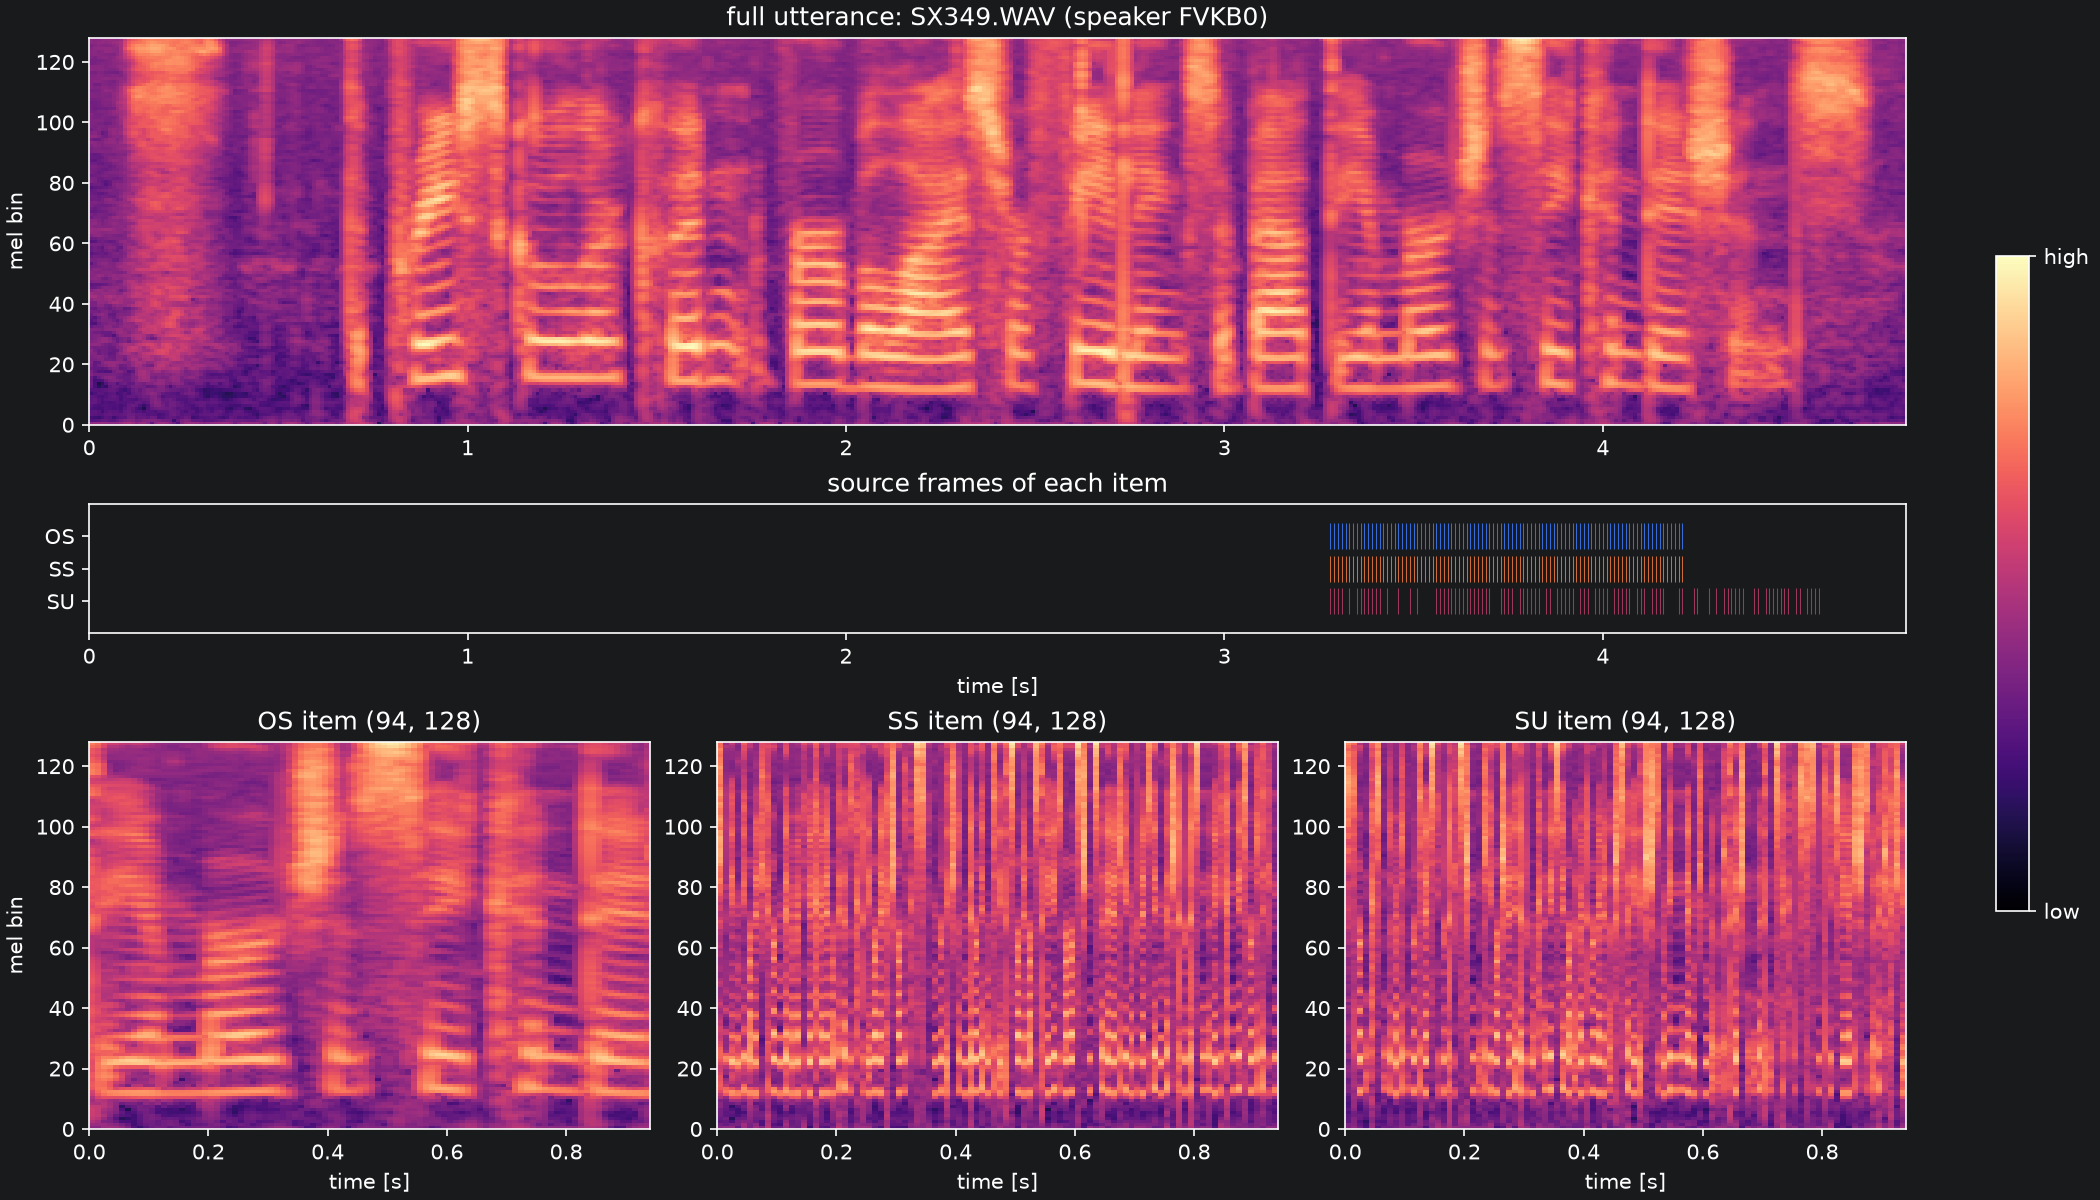

In [3]:
config = ExperimentConfig.from_yaml(config_path) if config_path else ExperimentConfig()
segment_length = config.data.segment_length(config.transformation)

# Utterance name (e.g. "SX150") -> its WAV files, one per speaker folder.
utterances = defaultdict(list)
for p in sorted(timit_train.rglob("*")):
    if p.suffix.lower() == ".wav":
        utterances[p.stem.upper()].append(p)
shared = sorted(name for name, paths in utterances.items() if len(paths) > 1)

rng = random.Random(seed)
output_dir = Path(tempfile.mkdtemp(prefix="debug-items-"))
for name in rng.sample(shared, n):
    paths = utterances[name]
    if len(paths) > max_speakers:
        paths = sorted(rng.sample(paths, max_speakers))
    display(Markdown(f"## {name} ({len(paths)} of {len(utterances[name])} speakers)"))
    for wav_path in paths:
        output_path = output_dir / f"{name}-{wav_path.parent.name}.png"
        plot_items(wav_path, output_path, segment_length, seed=seed, transformation=config.transformation,
                   normalise=normalise, full_only=full_only)
        print(wav_path.relative_to(timit_train))
        display(Image(filename=output_path))